# Checkpoint 3 — Inverse Problem via Emulator

**Goal:** given surface displacement measurements, recover:
- `layer_ID` — which layer contains the pressure anomaly (discrete, 0–3)
- `pressure_value` — anomaly pressure in [−0.5, 0.5]
- `center_location_mean` — cavity center (cx, cy)

**Strategy:**
1. Enumerate the 4 possible layers
2. For each layer, run L-BFGS-B with multiple random restarts over (pressure, cx, cy)
3. Pick the layer + parameters that minimise the L2 residual against the observed displacements

## 1 — Imports

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import joblib
from scipy.optimize import minimize
from scipy.interpolate import PchipInterpolator
from pathlib import Path

from create_grid import create_layered_grid_with_hole
from common_functions import solve_and_export_pressure

## 2 — Forward model setup (given code)

In [3]:
folder = Path.cwd()

mesh_size = 0.025

sd, cell_layer = create_layered_grid_with_hole(
    mesh_size=mesh_size, center=(1.5, 0.25)
)

folder_export = folder / "results"
layer_ID_true = 3
pressure_true = 0.5

u = solve_and_export_pressure(
    sd,
    cell_layer,
    layer_ID_true,
    pressure_true,
    folder_export,
    export_name="sol_layered_ID3",
    cell_data=[("layer", cell_layer.astype(float))],
)

print("u[0,:] shape:", np.shape(u[0, :]))

# Extraction of surface displacements
y_coords  = sd.nodes[1, :]
idx       = np.where(np.isclose(y_coords, 1.0))[0]
top_nodes = sd.nodes[0:2, idx]   # (2, N)  rows = [x ; y]
top_u     = u[0:2, idx]          # (2, N)  rows = [ux; uy]

print("top_nodes shape :", top_nodes.shape)
print("top_u shape     :", top_u.shape)
print("x range         :", top_nodes[0].min(), "to", top_nodes[0].max())

c:\Users\steto\anaconda3.1\envs\poresct4amm2526\Lib\site-packages\porepy\grids\mdg_generation.py:924: UserWarning: Found 51 fractures outside the domain boundary
  warn(f"Found {num_missing} fractures outside the domain boundary")


u[0,:] shape: (6256,)
top_nodes shape : (2, 83)
top_u shape     : (2, 83)
x range         : 0.0 to 2.0


## 3 — Diagnostics: verify GP model files exist

**Run this before anything else.** If any file is missing the inversion will fail with `None`.

In [4]:
# Point to your trained GP models
#MODELS_DIR = Path("/Users/edoardoventuroli/SCT4AMM/GeoMechLab/models")
# Cerca la cartella "models" nella stessa directory in cui si trova stefpy.py
_models_dir = Path.cwd() / "models"

# Confirm it exists before going any further
#assert MODELS_DIR.exists(), f"Models folder not found: {MODELS_DIR}"
assert _models_dir.exists(), f"Models folder not found: {_models_dir}"
print(f"Models directory: {_models_dir}")
def _load_models(layer_ID: int) -> dict:
    if layer_ID not in _gp_cache:
        ux_path = _models_dir / f"gp_ux_surf_layer_{layer_ID}.pkl"
        uy_path = _models_dir / f"gp_uy_surf_layer_{layer_ID}.pkl"
        if not ux_path.exists() or not uy_path.exists():
            raise FileNotFoundError(
                f"GP model files not found for layer {layer_ID}.\n"
                f"  Expected : {ux_path}\n"
                f"  Expected : {uy_path}"
            )
        _gp_cache[layer_ID] = {
            "ux": joblib.load(ux_path),
            "uy": joblib.load(uy_path),
        }
    return _gp_cache[layer_ID]
all_ok = True
for L in range(4):
    for component in ("ux", "uy"):
        p = _models_dir / f"gp_{component}_surf_layer_{L}.pkl"
        status = "OK" if p.exists() else "MISSING"
        print(f"  Layer {L} | {component} | {str(p):<60} {status}")
        if not p.exists():
            all_ok = False

print()
print("All 8 model files found." if all_ok else "WARNING: missing files above.")

Models directory: c:\Users\steto\SCT4AMM\GeoMechLab\models
  Layer 0 | ux | c:\Users\steto\SCT4AMM\GeoMechLab\models\gp_ux_surf_layer_0.pkl OK
  Layer 0 | uy | c:\Users\steto\SCT4AMM\GeoMechLab\models\gp_uy_surf_layer_0.pkl OK
  Layer 1 | ux | c:\Users\steto\SCT4AMM\GeoMechLab\models\gp_ux_surf_layer_1.pkl OK
  Layer 1 | uy | c:\Users\steto\SCT4AMM\GeoMechLab\models\gp_uy_surf_layer_1.pkl OK
  Layer 2 | ux | c:\Users\steto\SCT4AMM\GeoMechLab\models\gp_ux_surf_layer_2.pkl OK
  Layer 2 | uy | c:\Users\steto\SCT4AMM\GeoMechLab\models\gp_uy_surf_layer_2.pkl OK
  Layer 3 | ux | c:\Users\steto\SCT4AMM\GeoMechLab\models\gp_ux_surf_layer_3.pkl OK
  Layer 3 | uy | c:\Users\steto\SCT4AMM\GeoMechLab\models\gp_uy_surf_layer_3.pkl OK

All 8 model files found.


## 4 — GP emulator helpers

In [5]:
_gp_cache: dict = {}


def _load_models(layer_ID: int) -> dict:
    """Load and cache GP surface-displacement models for one layer."""
    if layer_ID not in _gp_cache:
        ux_path = _models_dir / f"gp_ux_surf_layer_{layer_ID}.pkl"
        uy_path = _models_dir / f"gp_uy_surf_layer_{layer_ID}.pkl"
        if not ux_path.exists() or not uy_path.exists():
            raise FileNotFoundError(
                f"GP model files not found for layer {layer_ID}.\n"
                f"  Expected : {ux_path}\n"
                f"  Expected : {uy_path}"
            )
        _gp_cache[layer_ID] = {
            "ux": joblib.load(ux_path),
            "uy": joblib.load(uy_path),
        }
    return _gp_cache[layer_ID]


def _emulator_surface(layer_ID: int, pressure: float, cx: float, cy: float):
    """Return (ux_vec, uy_vec) each shape (50,) on linspace(0,2,50)."""
    m = _load_models(layer_ID)
    X = np.array([[cx, cy, pressure]])
    return m["ux"].predict(X)[0], m["uy"].predict(X)[0]


_X_EVAL = np.linspace(0.0, 2.0, 50)


def _residual(params, layer_ID, x_obs, ux_obs, uy_obs):
    """L2 residual: emulator prediction vs observations."""
    pressure, cx, cy = params
    ux_pred, uy_pred = _emulator_surface(layer_ID, pressure, cx, cy)
    f_ux = PchipInterpolator(_X_EVAL, ux_pred)
    f_uy = PchipInterpolator(_X_EVAL, uy_pred)
    return float(
        np.sum((f_ux(x_obs) - ux_obs) ** 2) +
        np.sum((f_uy(x_obs) - uy_obs) ** 2)
    )


# Sanity check
try:
    _ux_t, _uy_t = _emulator_surface(0, 0.0, 1.0, 0.5)
    print(f"Emulator test OK — layer 0: ux shape {_ux_t.shape}, uy shape {_uy_t.shape}")
except FileNotFoundError as e:
    print(f"Emulator test FAILED (model files missing):\n{e}")
except Exception as e:
    print(f"Emulator test FAILED (unexpected error):\n{e}")

Emulator test OK — layer 0: ux shape (50,), uy shape (50,)


## 5 — `GroupSolutionCP3` (submission function)

Matches the provided template exactly:
```python
def GroupSolutionCP3(top_u, top_nodes) -> (layer_ID, pressure_value, center_location_mean)
```

In [6]:
def GroupSolutionCP3(top_u, top_nodes):
    """
    Inverse problem: recover the subsurface anomaly from surface displacement.

    Parameters
    ----------
    top_u     : np.ndarray, shape (2, N) — rows = [ux; uy]
    top_nodes : np.ndarray, shape (2, N) — rows = [x ; y]

    Returns
    -------
    layer_ID             : int
    pressure_value       : float
    center_location_mean : tuple (cx, cy)
    """
    # ── Reformat inputs ───────────────────────────────────────────
    x_obs  = np.asarray(top_nodes[0, :], dtype=float)
    ux_obs = np.asarray(top_u[0, :],     dtype=float)
    uy_obs = np.asarray(top_u[1, :],     dtype=float)

    # ── Settings ──────────────────────────────────────────────────
    bounds     = [(-0.5, 0.5), (0.1, 1.9), (0.1, 0.9)]   # pressure, cx, cy
    n_restarts = 15
    rng        = np.random.default_rng(42)

    best_overall_loss = np.inf
    best_layer        = None
    best_params       = None

    # ── Stage 1: enumerate layers ─────────────────────────────────
    for L in range(4):
        # Raise immediately if model files are missing — do NOT hide this
        _load_models(L)

        layer_best_loss   = np.inf
        layer_best_params = None

        # Random starts + one centred warm start
        p_inits  = rng.uniform(-0.5, 0.5, n_restarts)
        cx_inits = rng.uniform( 0.1, 1.9, n_restarts)
        cy_inits = rng.uniform( 0.1, 0.9, n_restarts)
        p_inits[0], cx_inits[0], cy_inits[0] = 0.0, 1.0, 0.5

        # ── Stage 2: multi-start L-BFGS-B ─────────────────────────
        for p0, cx0, cy0 in zip(p_inits, cx_inits, cy_inits):
            try:
                result = minimize(
                    _residual,
                    x0     = np.array([p0, cx0, cy0]),
                    args   = (L, x_obs, ux_obs, uy_obs),
                    method = "L-BFGS-B",
                    bounds = bounds,
                    options= {"maxiter": 200, "ftol": 1e-12, "gtol": 1e-8},
                )
                if result.fun < layer_best_loss:
                    layer_best_loss   = result.fun
                    layer_best_params = result.x.copy()
            except Exception as e:
                # Only swallow numerical errors, not missing-file errors
                print(f"  [Layer {L}] optimizer run failed: {e}")
                continue

        print(f"  Layer {L}: best loss = {layer_best_loss:.4e}  "
              f"params = {layer_best_params}")

        if layer_best_params is not None and layer_best_loss < best_overall_loss:
            best_overall_loss = layer_best_loss
            best_layer        = L
            best_params       = layer_best_params

    # ── Guard against total failure ───────────────────────────────
    if best_params is None:
        raise RuntimeError(
            "Inversion failed: no optimizer run succeeded across all 4 layers.\n"
            "Re-run cell 3 to check that all GP model files are present."
        )

    layer_ID             = best_layer
    pressure_value       = float(best_params[0])
    center_location_mean = (float(best_params[1]), float(best_params[2]))

    return layer_ID, pressure_value, center_location_mean

## 6 — Smoke-test on the forward simulation

In [7]:
est_layer, est_pressure, est_center = GroupSolutionCP3(top_u, top_nodes)

print()
print(f"Estimated layer    : {est_layer}       (true = {layer_ID_true})")
print(f"Estimated pressure : {est_pressure:+.4f}  (true = {pressure_true:+.4f})")
print(f"Estimated center   : ({est_center[0]:.4f}, {est_center[1]:.4f})  "
      f"(true = (1.5000, 0.2500))")

  Layer 0: best loss = 3.6259e-01  params = [0.29756349 1.04864286 0.89999855]
  Layer 1: best loss = 2.8543e-01  params = [0.4879418  1.11196078 0.89933858]
  Layer 2: best loss = 1.4489e-01  params = [0.5        1.37558612 0.9       ]
  Layer 3: best loss = 1.4064e-05  params = [0.5        1.32990743 0.29203809]

Estimated layer    : 3       (true = 3)
Estimated pressure : +0.5000  (true = +0.5000)
Estimated center   : (1.3299, 0.2920)  (true = (1.5000, 0.2500))


## 7 — Full validation against synthetic test cases

In [8]:
from stefpy import GroupSolutionCP2


def make_synthetic_obs(layer_ID, pressure, cx, cy, x_obs, noise_std=0.0):
    """
    Synthetic observations via the CP2 emulator.
    Returns shape (2, N) matching GroupSolutionCP3's input format.
    """
    mean_surf_func, _ = GroupSolutionCP2(
        layer_ID             = layer_ID,
        pressure_value       = pressure,
        center_location_mean = (cx, cy),
        center_location_std  = (0.01, 0.01),
    )
    disp = np.array([mean_surf_func(x) for x in x_obs]).T   # (2, N)
    if noise_std > 0:
        disp += np.random.default_rng(0).normal(0, noise_std, disp.shape)
    return disp

c:\Users\steto\anaconda3.1\envs\poresct4amm2526\Lib\site-packages\porepy\grids\mdg_generation.py:924: UserWarning: Found 51 fractures outside the domain boundary
  warn(f"Found {num_missing} fractures outside the domain boundary")


CP3 VALIDATION

──────────────────────────────────────────────────────────────────────
Test 1 | True: layer=3, p=+0.50, cx=1.5, cy=0.25
  Layer 0: best loss = 8.3303e-02  params = [0.30213647 1.09593709 0.88927203]
  Layer 1: best loss = 6.4968e-02  params = [0.48912068 1.11070256 0.89949807]
  Layer 2: best loss = 3.2330e-02  params = [0.5        1.36980622 0.9       ]
  Layer 3: best loss = 2.1862e-16  params = [0.5        1.50000071 0.24999896]
  Layer    : est=3  true=3  OK
  Pressure : est=+0.5000  true=+0.5000  |err|=0.0000
  cx       : est=1.5000   true=1.5000   |err|=0.0000
  cy       : est=0.2500   true=0.2500   |err|=0.0000


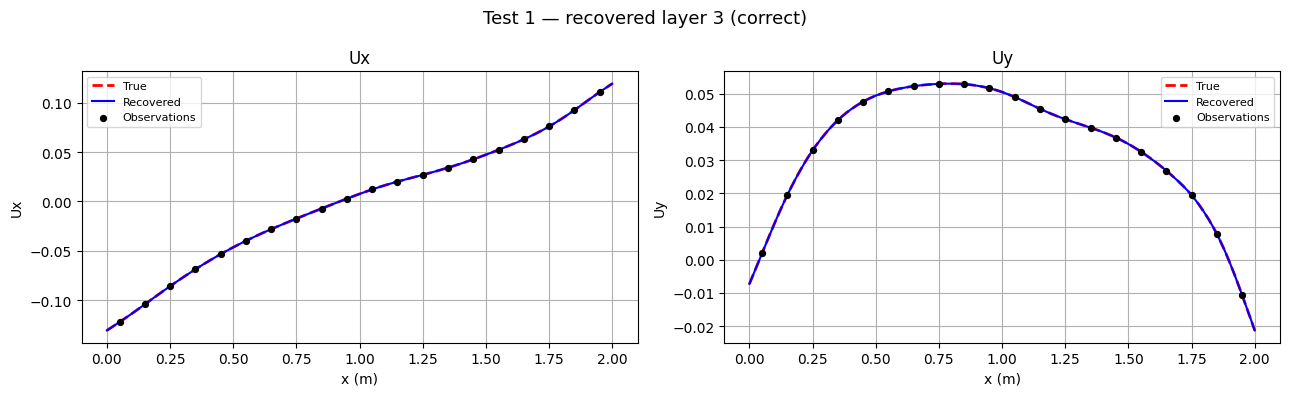


──────────────────────────────────────────────────────────────────────
Test 2 | True: layer=2, p=-0.30, cx=0.8, cy=0.5
  Layer 0: best loss = 4.5311e-03  params = [-0.20453069  1.9         0.1       ]
  Layer 1: best loss = 1.9494e-03  params = [-0.29114924  1.14009509  0.9       ]
  Layer 2: best loss = 5.5216e-16  params = [-0.30000003  0.79999944  0.49999996]
  Layer 3: best loss = 4.9104e-03  params = [-0.17814457  1.23437879  0.9       ]
  Layer    : est=2  true=2  OK
  Pressure : est=-0.3000  true=-0.3000  |err|=0.0000
  cx       : est=0.8000   true=0.8000   |err|=0.0000
  cy       : est=0.5000   true=0.5000   |err|=0.0000


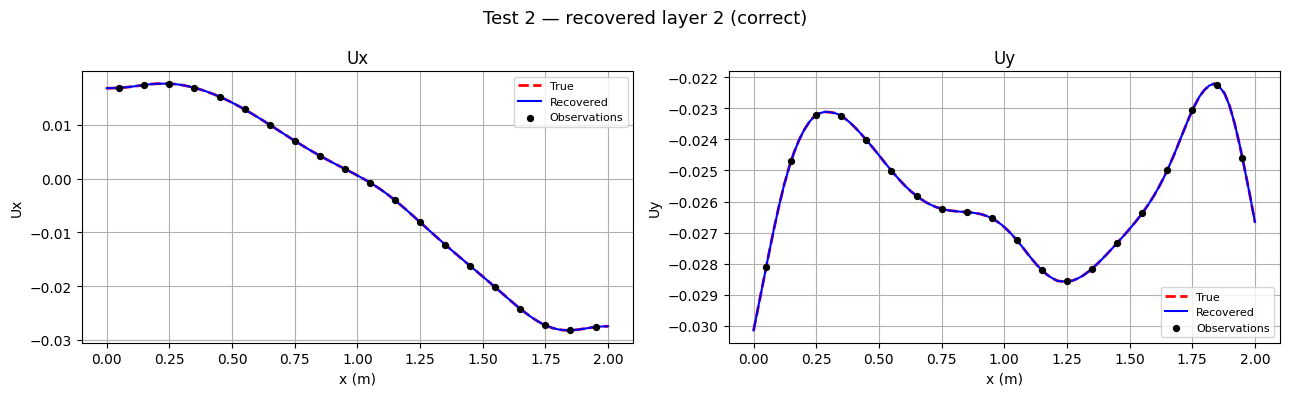


──────────────────────────────────────────────────────────────────────
Test 3 | True: layer=0, p=+0.40, cx=1.2, cy=0.35
  Layer 0: best loss = 2.0561e-14  params = [0.39999996 1.19999293 0.35000069]
  Layer 1: best loss = 1.6678e-03  params = [0.49544774 1.9        0.54120419]
  Layer 2: best loss = 1.2560e-02  params = [0.43500161 1.06088986 0.69822276]
  Layer 3: best loss = 3.6183e-02  params = [0.19100033 1.18844095 0.9       ]
  Layer    : est=0  true=0  OK
  Pressure : est=+0.4000  true=+0.4000  |err|=0.0000
  cx       : est=1.2000   true=1.2000   |err|=0.0000
  cy       : est=0.3500   true=0.3500   |err|=0.0000


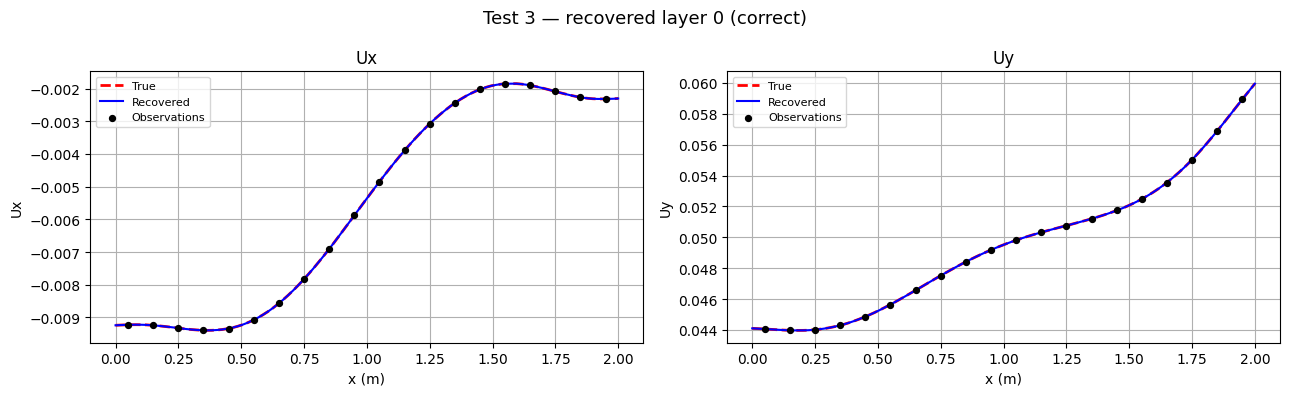


──────────────────────────────────────────────────────────────────────
Test 4 | True: layer=1, p=-0.45, cx=0.6, cy=0.6
  Layer 0: best loss = 1.8465e-03  params = [-0.33816319  1.9         0.1       ]
  Layer 1: best loss = 2.0649e-17  params = [-0.45000001  0.59999978  0.59999979]
  Layer 2: best loss = 3.6114e-03  params = [-0.41566422  1.0995099   0.70942837]
  Layer 3: best loss = 2.1662e-02  params = [-0.20033707  1.22360165  0.9       ]
  Layer    : est=1  true=1  OK
  Pressure : est=-0.4500  true=-0.4500  |err|=0.0000
  cx       : est=0.6000   true=0.6000   |err|=0.0000
  cy       : est=0.6000   true=0.6000   |err|=0.0000


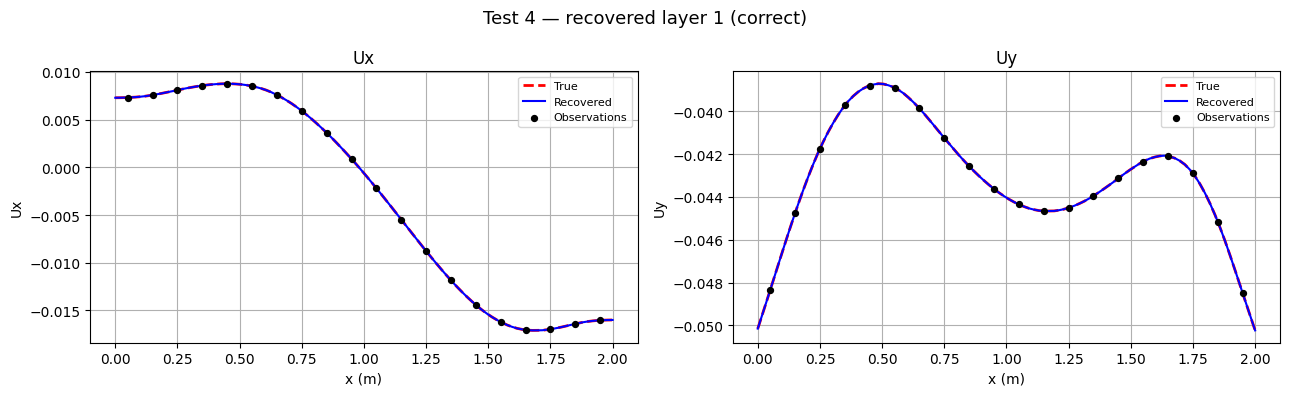


──────────────────────────────────────────────────────────────────────
Test 5 | True: layer=3, p=+0.20, cx=1.0, cy=0.4
  Layer 0: best loss = 1.3451e-02  params = [0.12094036 0.10120784 0.29520875]
  Layer 1: best loss = 1.0436e-02  params = [0.20004551 1.11252723 0.9       ]
  Layer 2: best loss = 4.4943e-03  params = [0.24736355 1.40251338 0.9       ]
  Layer 3: best loss = 1.8620e-13  params = [0.20000017 1.00003456 0.40008653]
  Layer    : est=3  true=3  OK
  Pressure : est=+0.2000  true=+0.2000  |err|=0.0000
  cx       : est=1.0000   true=1.0000   |err|=0.0000
  cy       : est=0.4001   true=0.4000   |err|=0.0001


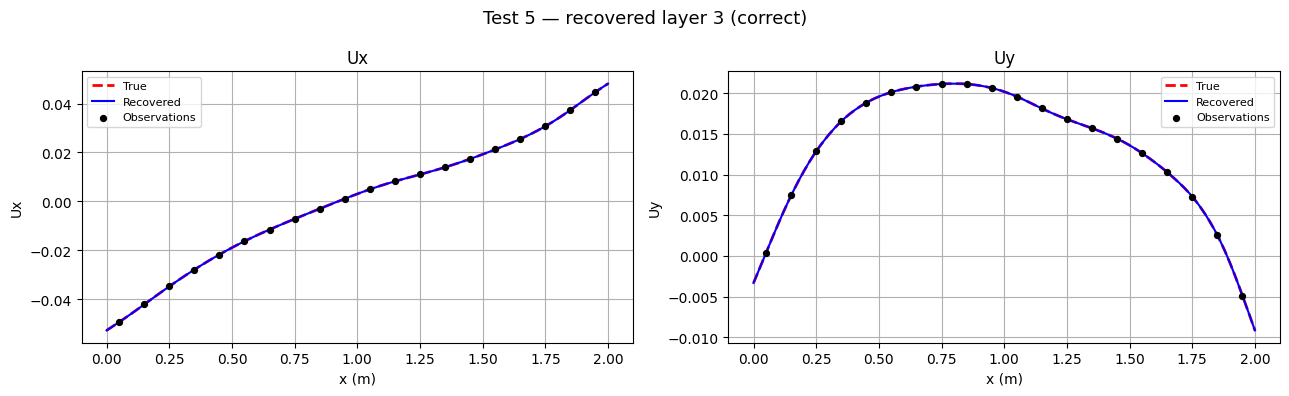


──────────────────────────────────────────────────────────────────────
Test 6 | True: layer=2, p=+0.13, cx=1.4, cy=0.1
  Layer 0: best loss = 1.0311e-03  params = [0.0889669  1.59619147 0.17787154]
  Layer 1: best loss = 3.7755e-04  params = [0.12833163 1.111862   0.9       ]
  Layer 2: best loss = 6.6712e-14  params = [0.12999934 1.40001738 0.10001838]
  Layer 3: best loss = 9.4480e-04  params = [0.07921448 1.33023307 0.9       ]
  Layer    : est=2  true=2  OK
  Pressure : est=+0.1300  true=+0.1300  |err|=0.0000
  cx       : est=1.4000   true=1.4000   |err|=0.0000
  cy       : est=0.1000   true=0.1000   |err|=0.0000


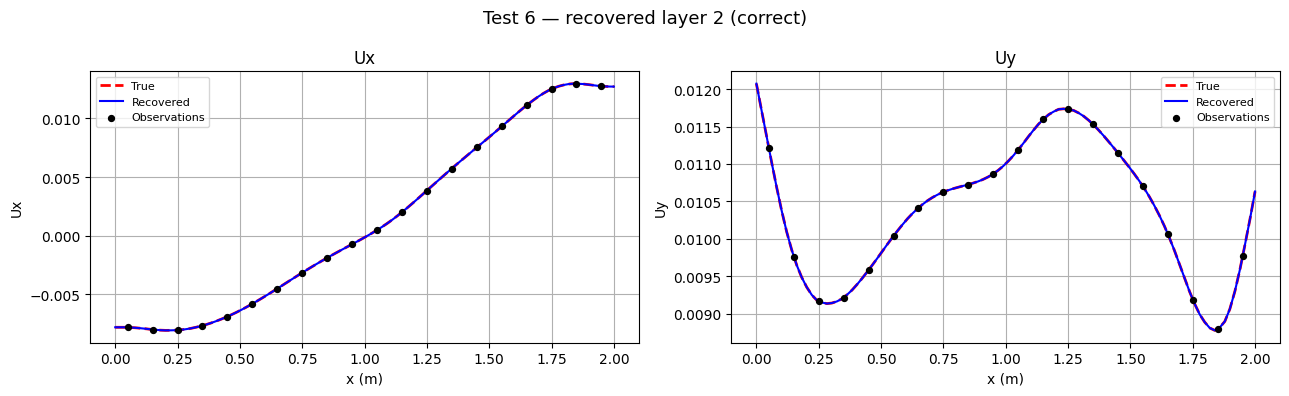


──────────────────────────────────────────────────────────────────────
Test 7 | True: layer=3, p=+0.02, cx=1.2, cy=0.28
  Layer 0: best loss = 1.2030e-04  params = [0.01187566 1.9        0.4083496 ]
  Layer 1: best loss = 6.9761e-05  params = [0.01966162 0.1        0.30014018]
  Layer 2: best loss = 3.4278e-05  params = [0.02204082 1.9        0.20190299]
  Layer 3: best loss = 1.2417e-09  params = [0.01994781 1.09820096 0.27000642]
  Layer    : est=3  true=3  OK
  Pressure : est=+0.0199  true=+0.0200  |err|=0.0001
  cx       : est=1.0982   true=1.2000   |err|=0.1018
  cy       : est=0.2700   true=0.2800   |err|=0.0100


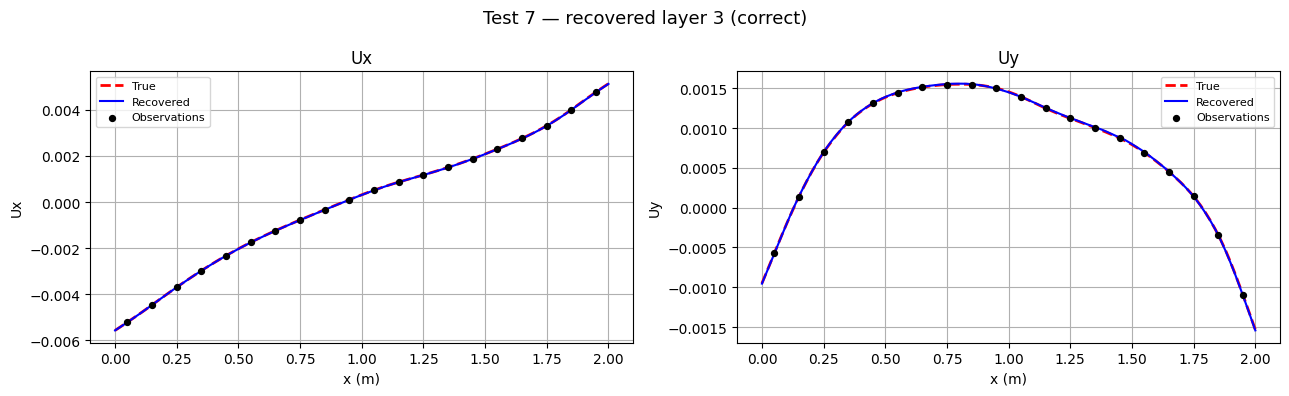


──────────────────────────────────────────────────────────────────────
Test 8 | True: layer=1, p=-0.48, cx=1.72, cy=0.65
  Layer 0: best loss = 1.8690e-03  params = [-0.36384238  1.9         0.1       ]
  Layer 1: best loss = 3.4373e-17  params = [-0.48000001  1.71999994  0.64999994]
  Layer 2: best loss = 4.1502e-03  params = [-0.44441499  1.09105251  0.7057688 ]
  Layer 3: best loss = 2.4606e-02  params = [-0.21601462  1.21776589  0.9       ]
  Layer    : est=1  true=1  OK
  Pressure : est=-0.4800  true=-0.4800  |err|=0.0000
  cx       : est=1.7200   true=1.7200   |err|=0.0000
  cy       : est=0.6500   true=0.6500   |err|=0.0000


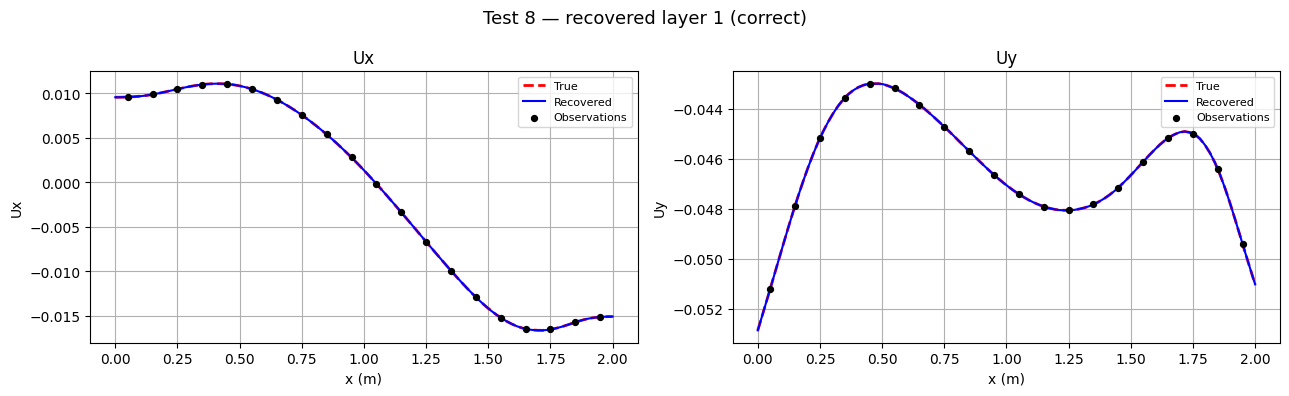


──────────────────────────────────────────────────────────────────────
Test 9 | True: layer=0, p=+0.50, cx=0.35, cy=0.85
  Layer 0: best loss = 1.0045e-07  params = [0.49974343 0.28206891 0.80857937]
  Layer 1: best loss = 5.6427e-03  params = [0.5        1.9        0.54036892]
  Layer 2: best loss = 2.0098e-02  params = [0.5        1.05464812 0.69301575]
  Layer 3: best loss = 5.6866e-02  params = [0.23822653 1.18648087 0.9       ]
  Layer    : est=0  true=0  OK
  Pressure : est=+0.4997  true=+0.5000  |err|=0.0003
  cx       : est=0.2821   true=0.3500   |err|=0.0679
  cy       : est=0.8086   true=0.8500   |err|=0.0414


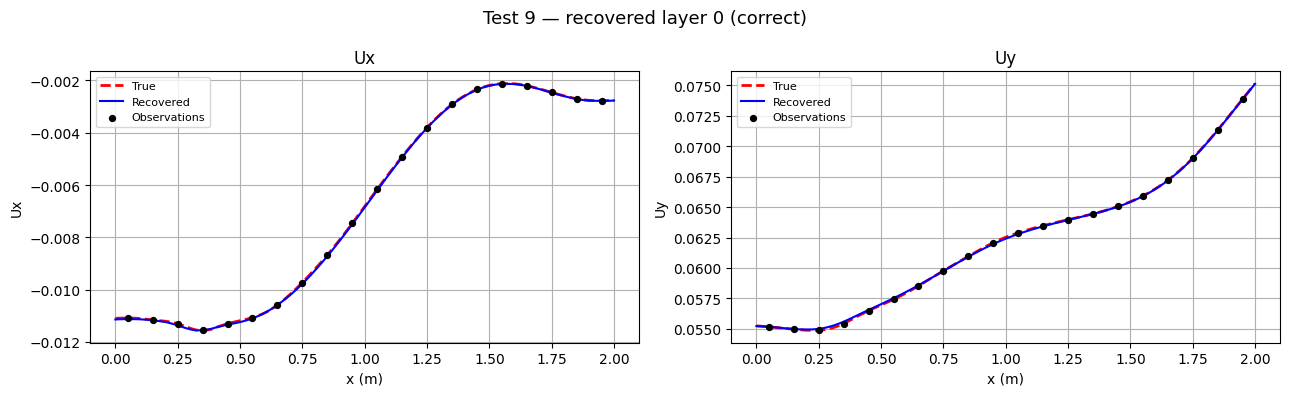


──────────────────────────────────────────────────────────────────────
Test 10 | True: layer=2, p=+0.00, cx=1.0, cy=0.5
  Layer 0: best loss = 1.6485e-07  params = [3.35858189e-04 2.00195226e-01 3.80521734e-01]
  Layer 1: best loss = 6.4518e-08  params = [2.48196284e-04 1.80553132e-01 4.67270240e-01]
  Layer 2: best loss = 0.0000e+00  params = [0.  1.  0.5]
  Layer 3: best loss = 1.7704e-07  params = [1.30610614e-04 9.95978181e-01 5.97814921e-01]
  Layer    : est=2  true=2  OK
  Pressure : est=+0.0000  true=+0.0000  |err|=0.0000
  cx       : est=1.0000   true=1.0000   |err|=0.0000
  cy       : est=0.5000   true=0.5000   |err|=0.0000


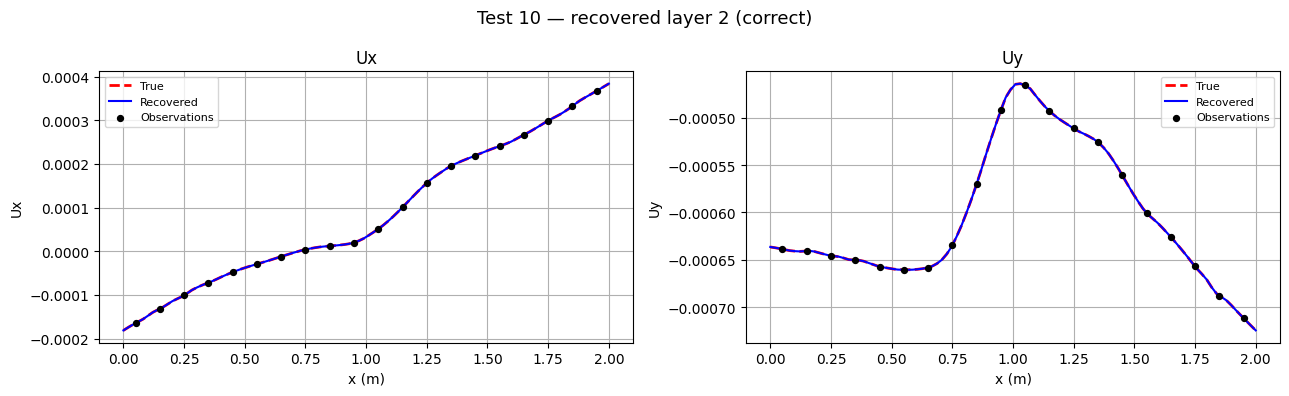

In [9]:
test_cases = [
    {"id": 1, "layer": 3, "press":  0.50, "cx": 1.50, "cy": 0.25},
    {"id": 2, "layer": 2, "press": -0.30, "cx": 0.80, "cy": 0.50},
    {"id": 3, "layer": 0, "press":  0.40, "cx": 1.20, "cy": 0.35},
    {"id": 4, "layer": 1, "press": -0.45, "cx": 0.60, "cy": 0.60},
    {"id": 5, "layer": 3, "press":  0.20, "cx": 1.00, "cy": 0.40},
    {"id": 6, "layer": 2, "press": 0.13, "cx": 1.40, "cy": 0.10},   # the next ones are some pathological cases
    {"id": 7, "layer": 3, "press": 0.02, "cx": 1.20, "cy": 0.28},   # ghost case
    {"id": 8, "layer": 1, "press": -0.48, "cx": 1.72, "cy": 0.65},  # asymetric case
    {"id": 9, "layer": 0, "press": 0.50, "cx": 0.35, "cy": 0.85},   # local minima
    {"id": 10, "layer": 2, "press": 0.00, "cx": 1.00, "cy": 0.50},  # grad(cx,cy) = 0
]

x_obs_val     = np.linspace(0.05, 1.95, 20)
top_nodes_val = np.vstack([x_obs_val, np.ones_like(x_obs_val)])  # (2, 20)

print("=" * 70)
print("CP3 VALIDATION")
print("=" * 70)

for tc in test_cases:
    print(f"\n{'─'*70}")
    print(f"Test {tc['id']} | True: layer={tc['layer']}, "
          f"p={tc['press']:+.2f}, cx={tc['cx']}, cy={tc['cy']}")

    top_u_synth = make_synthetic_obs(
        tc["layer"], tc["press"], tc["cx"], tc["cy"], x_obs_val
    )

    est_layer, est_p, (est_cx, est_cy) = GroupSolutionCP3(
        top_u_synth, top_nodes_val
    )

    layer_ok = est_layer == tc["layer"]
    print(f"  Layer    : est={est_layer}  true={tc['layer']}  "
          f"{'OK' if layer_ok else 'WRONG'}")
    print(f"  Pressure : est={est_p:+.4f}  true={tc['press']:+.4f}  "
          f"|err|={abs(est_p - tc['press']):.4f}")
    print(f"  cx       : est={est_cx:.4f}   true={tc['cx']:.4f}   "
          f"|err|={abs(est_cx - tc['cx']):.4f}")
    print(f"  cy       : est={est_cy:.4f}   true={tc['cy']:.4f}   "
          f"|err|={abs(est_cy - tc['cy']):.4f}")

    # Plot
    x_plot = np.linspace(0, 2, 100)
    rec_func,  _ = GroupSolutionCP2(
        layer_ID=est_layer, pressure_value=est_p,
        center_location_mean=(est_cx, est_cy), center_location_std=(0.01, 0.01),
    )
    true_func, _ = GroupSolutionCP2(
        layer_ID=tc["layer"], pressure_value=tc["press"],
        center_location_mean=(tc["cx"], tc["cy"]), center_location_std=(0.01, 0.01),
    )

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    fig.suptitle(
        f"Test {tc['id']} — recovered layer {est_layer} "
        f"({'correct' if layer_ok else 'WRONG, true=' + str(tc['layer'])})",
        fontsize=13,
    )
    for ax, row, label in zip(axes, [0, 1], ["Ux", "Uy"]):
        ax.plot(x_plot, [true_func(x)[row] for x in x_plot],
                "r--", lw=2, label="True")
        ax.plot(x_plot, [rec_func(x)[row] for x in x_plot],
                "b-",  lw=1.5, label="Recovered")
        ax.scatter(x_obs_val, top_u_synth[row, :],
                   s=18, c="k", zorder=5, label="Observations")
        ax.set_xlabel("x (m)"); ax.set_ylabel(label)
        ax.set_title(label); ax.legend(fontsize=8); ax.grid(True)
    plt.tight_layout()
    plt.show()

  Layer 0: best loss = 8.3303e-02  params = [0.30213647 1.09593709 0.88927203]
  Layer 1: best loss = 6.4968e-02  params = [0.48912068 1.11070256 0.89949807]
  Layer 2: best loss = 3.2330e-02  params = [0.5        1.36980622 0.9       ]
  Layer 3: best loss = 2.1862e-16  params = [0.5        1.50000071 0.24999896]
  Layer 0: best loss = 4.5311e-03  params = [-0.20453069  1.9         0.1       ]
  Layer 1: best loss = 1.9494e-03  params = [-0.29114924  1.14009509  0.9       ]
  Layer 2: best loss = 5.5216e-16  params = [-0.30000003  0.79999944  0.49999996]
  Layer 3: best loss = 4.9104e-03  params = [-0.17814457  1.23437879  0.9       ]
  Layer 0: best loss = 2.0561e-14  params = [0.39999996 1.19999293 0.35000069]
  Layer 1: best loss = 1.6678e-03  params = [0.49544774 1.9        0.54120419]
  Layer 2: best loss = 1.2560e-02  params = [0.43500161 1.06088986 0.69822276]
  Layer 3: best loss = 3.6183e-02  params = [0.19100033 1.18844095 0.9       ]
  Layer 0: best loss = 1.8465e-03  param

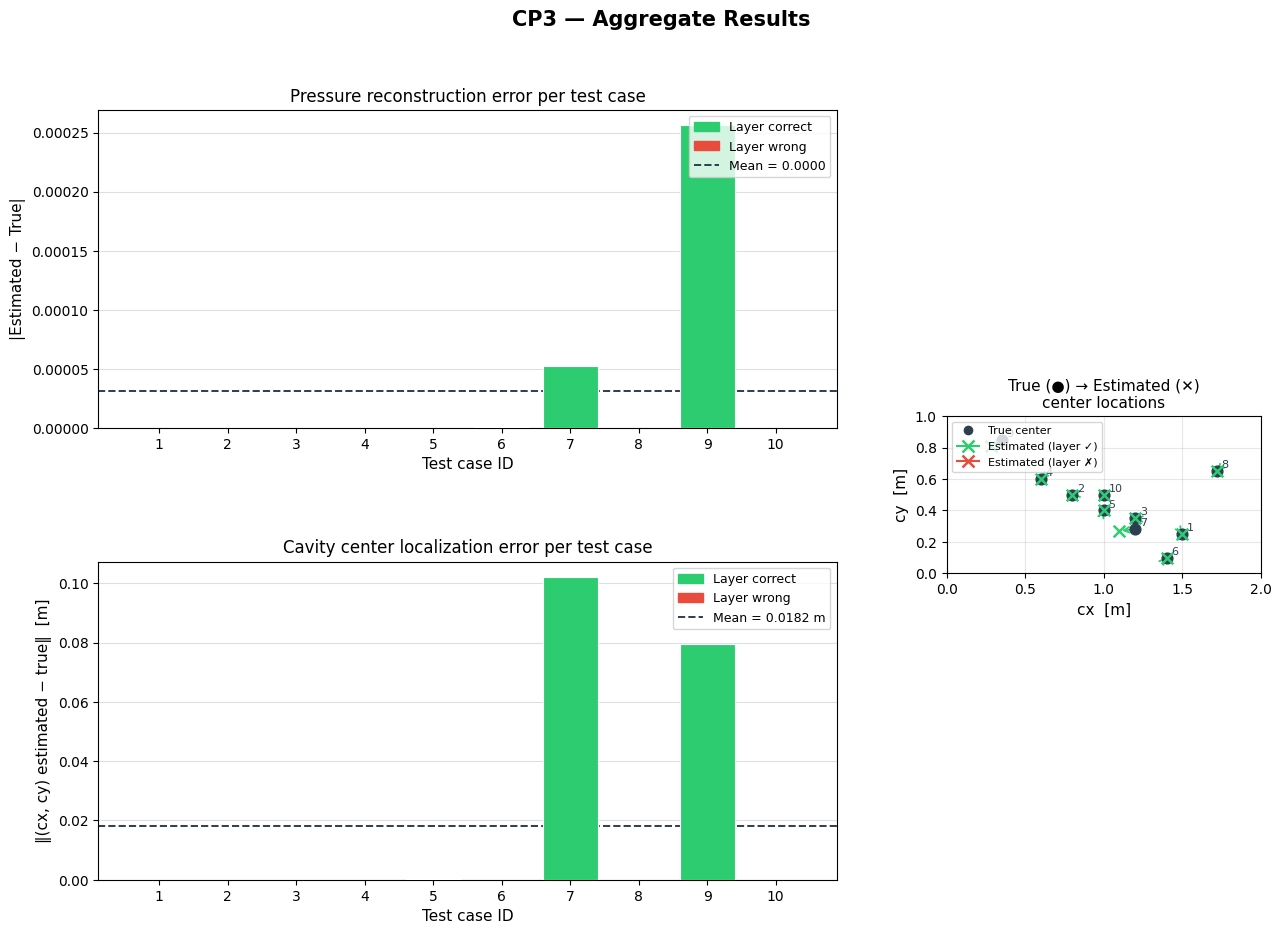

Figure saved to cp3_summary.png


In [10]:
# ── SUMMARY CELL ─────────────────────────────────────────────────────────────
# Run this cell AFTER the validation loop (cell 15) has already populated
# `test_cases`, `x_obs_val`, `top_nodes_val` and the helper functions.
# It collects results, prints a summary table, and shows two aggregate plots.
# ─────────────────────────────────────────────────────────────────────────────

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec

# ── 1. Re-run inversion for all test cases and collect results ────────────────
records = []

for tc in test_cases:
    top_u_synth = make_synthetic_obs(
        tc["layer"], tc["press"], tc["cx"], tc["cy"], x_obs_val
    )
    est_layer, est_p, (est_cx, est_cy) = GroupSolutionCP3(
        top_u_synth, top_nodes_val
    )
    records.append({
        "id":           tc["id"],
        "true_layer":   tc["layer"],
        "est_layer":    est_layer,
        "layer_ok":     est_layer == tc["layer"],
        "true_p":       tc["press"],
        "est_p":        est_p,
        "err_p":        abs(est_p - tc["press"]),
        "true_cx":      tc["cx"],
        "est_cx":       est_cx,
        "err_cx":       abs(est_cx - tc["cx"]),
        "true_cy":      tc["cy"],
        "est_cy":       est_cy,
        "err_cy":       abs(est_cy - tc["cy"]),
        "err_center":   np.sqrt((est_cx - tc["cx"])**2 + (est_cy - tc["cy"])**2),
    })

# ── 2. Summary table ──────────────────────────────────────────────────────────
header = (
    f"{'ID':>3}  {'True L':>6}  {'Est L':>5}  {'✓':>2}  "
    f"{'True p':>7}  {'Est p':>7}  {'|Δp|':>6}  "
    f"{'True cx':>7}  {'Est cx':>7}  {'|Δcx|':>6}  "
    f"{'True cy':>7}  {'Est cy':>7}  {'|Δcy|':>6}  "
    f"{'‖Δc‖':>6}"
)
sep = "─" * len(header)

print()
print("=" * len(header))
print("  CP3 — RESULTS SUMMARY")
print("=" * len(header))
print(header)
print(sep)

for r in records:
    tick = "✓" if r["layer_ok"] else "✗"
    print(
        f"{r['id']:>3}  {r['true_layer']:>6}  {r['est_layer']:>5}  {tick:>2}  "
        f"{r['true_p']:>+7.3f}  {r['est_p']:>+7.3f}  {r['err_p']:>6.4f}  "
        f"{r['true_cx']:>7.4f}  {r['est_cx']:>7.4f}  {r['err_cx']:>6.4f}  "
        f"{r['true_cy']:>7.4f}  {r['est_cy']:>7.4f}  {r['err_cy']:>6.4f}  "
        f"{r['err_center']:>6.4f}"
    )

print(sep)

n          = len(records)
n_ok       = sum(r["layer_ok"]   for r in records)
mean_ep    = np.mean([r["err_p"]      for r in records])
max_ep     = np.max( [r["err_p"]      for r in records])
mean_ec    = np.mean([r["err_center"] for r in records])
max_ec     = np.max( [r["err_center"] for r in records])

print(
    f"\n  Layer accuracy   : {n_ok}/{n} ({100*n_ok/n:.0f}%)\n"
    f"  Pressure |error| : mean = {mean_ep:.4f}   max = {max_ep:.4f}\n"
    f"  Center   ‖error‖ : mean = {mean_ec:.4f} m   max = {max_ec:.4f} m"
)
print("=" * len(header))


# ── 3. Aggregate plots ────────────────────────────────────────────────────────
ids        = [r["id"]         for r in records]
err_p      = [r["err_p"]      for r in records]
err_center = [r["err_center"] for r in records]
layer_ok   = [r["layer_ok"]   for r in records]
colors     = ["#2ecc71" if ok else "#e74c3c" for ok in layer_ok]

fig = plt.figure(figsize=(15, 10))
fig.suptitle("CP3 — Aggregate Results", fontsize=15, fontweight="bold", y=0.98)
gs  = GridSpec(2, 3, figure=fig, hspace=0.42, wspace=0.35)

# ── 3a. Pressure error bar chart ──────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, :2])
bars = ax1.bar(ids, err_p, color=colors, edgecolor="white", linewidth=0.8, zorder=3)
ax1.axhline(mean_ep, color="#2c3e50", ls="--", lw=1.4,
            label=f"Mean error = {mean_ep:.4f}")
ax1.set_xlabel("Test case ID", fontsize=11)
ax1.set_ylabel("|Estimated − True|", fontsize=11)
ax1.set_title("Pressure reconstruction error per test case", fontsize=12)
ax1.set_xticks(ids)
ax1.grid(axis="y", alpha=0.4, zorder=0)
ax1.legend(fontsize=10)

patch_ok  = mpatches.Patch(color="#2ecc71", label="Layer correct")
patch_bad = mpatches.Patch(color="#e74c3c", label="Layer wrong")
ax1.legend(handles=[patch_ok, patch_bad,
                    plt.Line2D([0],[0], color="#2c3e50", ls="--", lw=1.4,
                               label=f"Mean = {mean_ep:.4f}")],
           fontsize=9, loc="upper right")

# ── 3b. Center error bar chart ────────────────────────────────────────────────
ax2 = fig.add_subplot(gs[1, :2])
ax2.bar(ids, err_center, color=colors, edgecolor="white", linewidth=0.8, zorder=3)
ax2.axhline(mean_ec, color="#2c3e50", ls="--", lw=1.4,
            label=f"Mean error = {mean_ec:.4f} m")
ax2.set_xlabel("Test case ID", fontsize=11)
ax2.set_ylabel("‖(cx, cy) estimated − true‖  [m]", fontsize=11)
ax2.set_title("Cavity center localization error per test case", fontsize=12)
ax2.set_xticks(ids)
ax2.grid(axis="y", alpha=0.4, zorder=0)
ax2.legend(handles=[patch_ok, patch_bad,
                    plt.Line2D([0],[0], color="#2c3e50", ls="--", lw=1.4,
                               label=f"Mean = {mean_ec:.4f} m")],
           fontsize=9, loc="upper right")

# ── 3c. Scatter: true vs estimated center ─────────────────────────────────────
ax3 = fig.add_subplot(gs[:, 2])
for r in records:
    c  = "#2ecc71" if r["layer_ok"] else "#e74c3c"
    ax3.annotate(
        "", xy=(r["est_cx"], r["est_cy"]),
        xytext=(r["true_cx"], r["true_cy"]),
        arrowprops=dict(arrowstyle="->", color=c, lw=1.3),
    )
    ax3.scatter(r["true_cx"], r["true_cy"],
                marker="o", s=60, color="#2c3e50", zorder=4)
    ax3.scatter(r["est_cx"], r["est_cy"],
                marker="x", s=70, color=c, linewidths=1.8, zorder=4)
    ax3.text(r["true_cx"] + 0.03, r["true_cy"] + 0.02,
             str(r["id"]), fontsize=8, color="#2c3e50")

ax3.set_xlim(0, 2)
ax3.set_ylim(0, 1)
ax3.set_xlabel("cx  [m]", fontsize=11)
ax3.set_ylabel("cy  [m]", fontsize=11)
ax3.set_title("True (●) → Estimated (✕)\ncenter locations", fontsize=11)
ax3.grid(alpha=0.3)
ax3.set_aspect("equal")
ax3.legend(handles=[
    plt.Line2D([0],[0], marker="o", color="w", markerfacecolor="#2c3e50",
               markersize=8, label="True center"),
    plt.Line2D([0],[0], marker="x", color="#2ecc71", markersize=8,
               markeredgewidth=1.8, label="Estimated (layer ✓)"),
    plt.Line2D([0],[0], marker="x", color="#e74c3c", markersize=8,
               markeredgewidth=1.8, label="Estimated (layer ✗)"),
], fontsize=8, loc="upper left")

plt.savefig("cp3_summary.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved to cp3_summary.png")

  Layer 0: best loss = 8.3303e-02  params = [0.30213647 1.09593709 0.88927203]
  Layer 1: best loss = 6.4968e-02  params = [0.48912068 1.11070256 0.89949807]
  Layer 2: best loss = 3.2330e-02  params = [0.5        1.36980622 0.9       ]
  Layer 3: best loss = 2.1862e-16  params = [0.5        1.50000071 0.24999896]
  Layer 0: best loss = 4.5311e-03  params = [-0.20453069  1.9         0.1       ]
  Layer 1: best loss = 1.9494e-03  params = [-0.29114924  1.14009509  0.9       ]
  Layer 2: best loss = 5.5216e-16  params = [-0.30000003  0.79999944  0.49999996]
  Layer 3: best loss = 4.9104e-03  params = [-0.17814457  1.23437879  0.9       ]
  Layer 0: best loss = 2.0561e-14  params = [0.39999996 1.19999293 0.35000069]
  Layer 1: best loss = 1.6678e-03  params = [0.49544774 1.9        0.54120419]
  Layer 2: best loss = 1.2560e-02  params = [0.43500161 1.06088986 0.69822276]
  Layer 3: best loss = 3.6183e-02  params = [0.19100033 1.18844095 0.9       ]
  Layer 0: best loss = 1.8465e-03  param

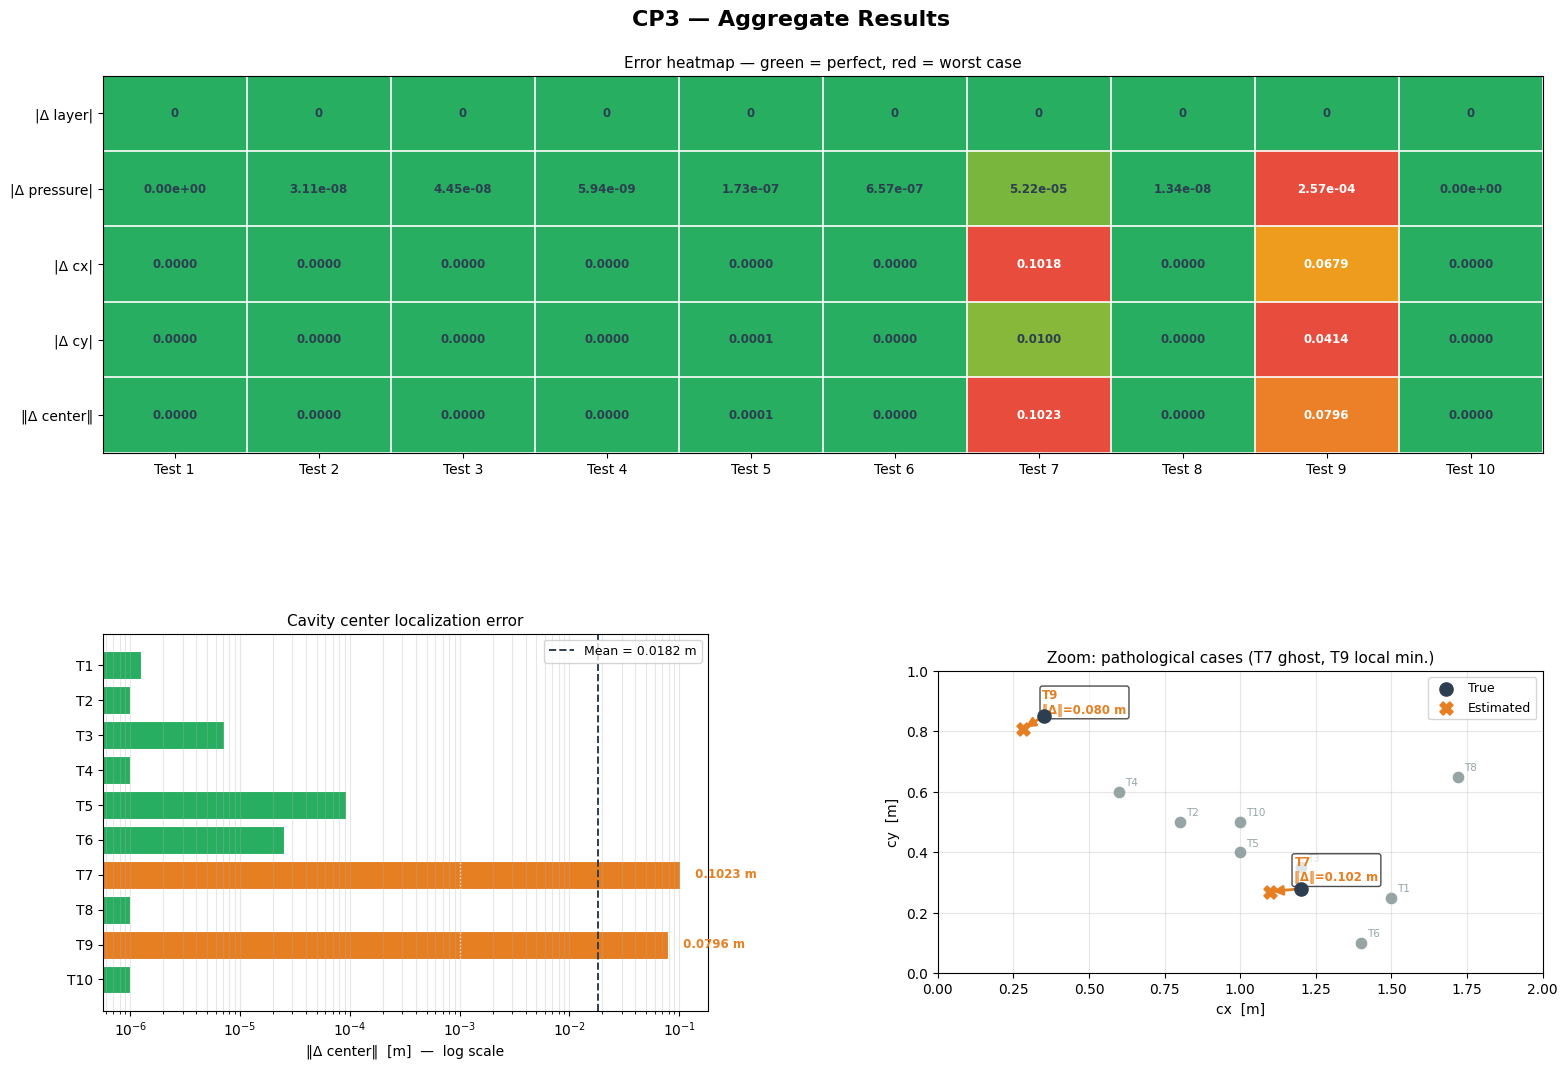

Figure saved → cp3_summary_v2.png


In [11]:
# ── SUMMARY CELL v2 ──────────────────────────────────────────────────────────
# Run AFTER il loop di validazione (cell 15) ha già eseguito.
# ─────────────────────────────────────────────────────────────────────────────

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec

# ── 1. Re-run inversion e raccolta risultati ──────────────────────────────────
records = []
for tc in test_cases:
    top_u_synth = make_synthetic_obs(
        tc["layer"], tc["press"], tc["cx"], tc["cy"], x_obs_val
    )
    est_layer, est_p, (est_cx, est_cy) = GroupSolutionCP3(
        top_u_synth, top_nodes_val
    )
    records.append({
        "id":         tc["id"],
        "true_layer": tc["layer"],  "est_layer":  est_layer,
        "layer_ok":   est_layer == tc["layer"],
        "true_p":     tc["press"],  "est_p":      est_p,
        "err_p":      abs(est_p - tc["press"]),
        "true_cx":    tc["cx"],     "est_cx":     est_cx,
        "true_cy":    tc["cy"],     "est_cy":     est_cy,
        "err_cx":     abs(est_cx - tc["cx"]),
        "err_cy":     abs(est_cy - tc["cy"]),
        "err_center": np.sqrt((est_cx-tc["cx"])**2 + (est_cy-tc["cy"])**2),
    })

# ── Stampa tabella testuale ───────────────────────────────────────────────────
header = (
    f"{'ID':>3}  {'True L':>6}  {'Est L':>5}  {'✓':>2}  "
    f"{'True p':>7}  {'Est p':>7}  {'|Δp|':>8}  "
    f"{'True cx':>7}  {'Est cx':>7}  {'|Δcx|':>6}  "
    f"{'True cy':>7}  {'Est cy':>7}  {'|Δcy|':>6}  {'‖Δc‖':>8}"
)
sep = "─" * len(header)
print(); print("=" * len(header))
print("  CP3 — RESULTS SUMMARY")
print("=" * len(header)); print(header); print(sep)
for r in records:
    tick = "✓" if r["layer_ok"] else "✗"
    print(
        f"{r['id']:>3}  {r['true_layer']:>6}  {r['est_layer']:>5}  {tick:>2}  "
        f"{r['true_p']:>+7.3f}  {r['est_p']:>+7.3f}  {r['err_p']:>8.2e}  "
        f"{r['true_cx']:>7.4f}  {r['est_cx']:>7.4f}  {r['err_cx']:>6.4f}  "
        f"{r['true_cy']:>7.4f}  {r['est_cy']:>7.4f}  {r['err_cy']:>6.4f}  "
        f"{r['err_center']:>8.4f}"
    )
print(sep)
n_ok   = sum(r["layer_ok"]   for r in records)
mean_p = np.mean([r["err_p"]      for r in records])
max_p  = np.max( [r["err_p"]      for r in records])
mean_c = np.mean([r["err_center"] for r in records])
max_c  = np.max( [r["err_center"] for r in records])
print(f"\n  Layer accuracy   : {n_ok}/{len(records)} ({100*n_ok/len(records):.0f}%)")
print(f"  Pressure |error| : mean = {mean_p:.2e}   max = {max_p:.2e}")
print(f"  Center   ‖error‖ : mean = {mean_c:.4f} m   max = {max_c:.4f} m")
print("=" * len(header))

# ═══════════════════════════════════════════════════════════════════════════════
# FIGURE
# ═══════════════════════════════════════════════════════════════════════════════
ids = [r["id"] for r in records]

fig = plt.figure(figsize=(16, 11))
fig.suptitle("CP3 — Aggregate Results", fontsize=16, fontweight="bold", y=0.98)
gs  = GridSpec(2, 2, figure=fig, hspace=0.48, wspace=0.38,
               left=0.07, right=0.97, top=0.92, bottom=0.07)

# ── PALETTE ───────────────────────────────────────────────────────────────────
C_GOOD  = "#27ae60"
C_WARN  = "#e67e22"
C_BAD   = "#e74c3c"
C_DARK  = "#2c3e50"
C_GRID  = "#ecf0f1"

# ─────────────────────────────────────────────────────────────────────────────
# PLOT 1 — Heatmap degli errori (tabella grafica)
# ─────────────────────────────────────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, :])

metrics      = ["|Δ layer|", "|Δ pressure|", "|Δ cx|", "|Δ cy|", "‖Δ center‖"]
data_matrix  = np.array([
    [0.0 if r["layer_ok"] else 1.0,
     r["err_p"],
     r["err_cx"],
     r["err_cy"],
     r["err_center"]]
    for r in records
], dtype=float)   # shape (10, 5)

# Normalizza ogni colonna in [0,1] per il colore
col_max = np.where(data_matrix.max(axis=0) > 0, data_matrix.max(axis=0), 1.0)
norm_matrix = data_matrix / col_max

# Colormap: verde → arancio → rosso
cmap = mcolors.LinearSegmentedColormap.from_list(
    "gwr", ["#27ae60", "#f1c40f", "#e74c3c"]
)

im = ax1.imshow(norm_matrix.T, cmap=cmap, aspect="auto", vmin=0, vmax=1)

ax1.set_xticks(range(len(records)))
ax1.set_xticklabels([f"Test {r['id']}" for r in records], fontsize=10)
ax1.set_yticks(range(len(metrics)))
ax1.set_yticklabels(metrics, fontsize=10)
ax1.set_title("Error heatmap — green = perfect, red = worst case", fontsize=11)

# Annota ogni cella con il valore numerico
formats = ["{:.0f}", "{:.2e}", "{:.4f}", "{:.4f}", "{:.4f}"]
for j, (metric, fmt) in enumerate(zip(metrics, formats)):
    for i, r in enumerate(records):
        val  = data_matrix[i, j]
        text = fmt.format(val)
        # Testo bianco su sfondo scuro, nero su sfondo chiaro
        brightness = norm_matrix[i, j]
        tc = "white" if brightness > 0.55 else C_DARK
        ax1.text(i, j, text, ha="center", va="center",
                 fontsize=8.5, color=tc, fontweight="bold")

# Griglia sottile tra le celle
for x in np.arange(-0.5, len(records), 1):
    ax1.axvline(x, color="white", lw=1.2)
for y in np.arange(-0.5, len(metrics), 1):
    ax1.axhline(y, color="white", lw=1.2)

# ─────────────────────────────────────────────────────────────────────────────
# PLOT 2 — Bar chart orizzontale errore centro (log scale)
# ─────────────────────────────────────────────────────────────────────────────
ax2 = fig.add_subplot(gs[1, 0])

err_c  = [r["err_center"] for r in records]
labels = [f"T{r['id']}" for r in records]
colors = [C_WARN if r["id"] in (7, 9) else C_GOOD for r in records]

# Sostituiamo gli zero con un piccolo epsilon per la scala log
err_c_plot = [max(e, 1e-6) for e in err_c]

bars = ax2.barh(labels[::-1], err_c_plot[::-1],
                color=colors[::-1], edgecolor="white", linewidth=0.8)

ax2.set_xscale("log")
ax2.set_xlabel("‖Δ center‖  [m]  —  log scale", fontsize=10)
ax2.set_title("Cavity center localization error", fontsize=11)
ax2.axvline(mean_c, color=C_DARK, ls="--", lw=1.4,
            label=f"Mean = {mean_c:.4f} m")
ax2.axvline(1e-3, color=C_GRID, ls=":", lw=1)
ax2.grid(axis="x", alpha=0.3, which="both")
ax2.legend(fontsize=9)

# Etichetta sui casi patologici
for r, bar in zip(records[::-1], bars):
    if r["id"] in (7, 9):
        ax2.text(r["err_center"] * 1.15, bar.get_y() + bar.get_height()/2,
                 f"  {r['err_center']:.4f} m",
                 va="center", fontsize=8.5, color=C_WARN, fontweight="bold")

# ─────────────────────────────────────────────────────────────────────────────
# PLOT 3 — Zoom sui casi difficili: scatter cx vs cy errore
# ─────────────────────────────────────────────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 1])

hard_ids = (7, 9)
hard     = [r for r in records if r["id"] in hard_ids]
easy     = [r for r in records if r["id"] not in hard_ids]

# Casi facili: punto quasi sovrapposto → solo cerchio vero
for r in easy:
    ax3.scatter(r["true_cx"], r["true_cy"],
                s=55, color="#95a5a6", zorder=3, marker="o")
    ax3.text(r["true_cx"]+0.02, r["true_cy"]+0.02,
             f"T{r['id']}", fontsize=7.5, color="#95a5a6")

# Casi difficili: freccia true → estimated
for r in hard:
    ax3.annotate(
        "", xy=(r["est_cx"], r["est_cy"]),
        xytext=(r["true_cx"], r["true_cy"]),
        arrowprops=dict(arrowstyle="-|>", color=C_WARN, lw=2.0,
                        mutation_scale=14),
        zorder=5,
    )
    ax3.scatter(r["true_cx"], r["true_cy"],
                s=90, color=C_DARK, zorder=6, marker="o",
                label="True" if r == hard[0] else "")
    ax3.scatter(r["est_cx"], r["est_cy"],
                s=90, color=C_WARN, zorder=6, marker="X",
                label="Estimated" if r == hard[0] else "")
    # Annotazione con errore
    mid_x = (r["true_cx"] + r["est_cx"]) / 2
    mid_y = (r["true_cy"] + r["est_cy"]) / 2
    ax3.text(mid_x + 0.03, mid_y + 0.03,
             f"T{r['id']}\n‖Δ‖={r['err_center']:.3f} m",
             fontsize=8.5, color=C_WARN, fontweight="bold",
             bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7))

ax3.set_xlim(0, 2); ax3.set_ylim(0, 1)
ax3.set_xlabel("cx  [m]", fontsize=10)
ax3.set_ylabel("cy  [m]", fontsize=10)
ax3.set_title("Zoom: pathological cases (T7 ghost, T9 local min.)", fontsize=11)
ax3.set_aspect("equal")
ax3.grid(alpha=0.3)
ax3.legend(fontsize=9, loc="upper right")

plt.savefig("cp3_summary_v2.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved → cp3_summary_v2.png")